In [1]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.18.1
Keras: 3.15.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
MAX_UNKNOWN = 1.0 # 1.0 = keep every training tile try 0.5 to drop tiles

In [3]:
import sys
sys.path.append("../scripts")
from dataset import get_tiles, SPLITS
X_train, y_train = get_tiles(SPLITS["train"], stride=128,
                             max_unknown=MAX_UNKNOWN)

# Val and test no overlap, keep every tile (the defaults)
X_val, y_val = get_tiles(SPLITS["val"])
X_test, y_test = get_tiles(SPLITS["test"])

In [4]:
import numpy as np

for name, X, y in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    unknown = (y == -1).mean()
    known = y[y != -1]
    print(f"{name:5}  X {X.shape}  y {y.shape}  unknown {unknown:.1%}  flood (of known) {known.mean():.1%}")

Train  X (1972, 256, 256, 4)  y (1972, 256, 256)  unknown 23.7%  flood (of known) 55.7%
Val    X (110, 256, 256, 4)  y (110, 256, 256)  unknown 20.0%  flood (of known) 51.3%
Test   X (287, 256, 256, 4)  y (287, 256, 256)  unknown 48.5%  flood (of known) 76.0%


In [5]:
#make copy of the training tiles that keeps only the rgb channels and leaves out the dem part

X_train_rgb = X_train[..., :3]
X_val_rgb = X_val[..., :3]
X_test_rgb = X_test[..., :3]

print(X_train_rgb.shape, X_val_rgb.shape, X_test_rgb.shape)
print("RGB min:", X_train_rgb.min(), "max:", X_train_rgb.max())

(1972, 256, 256, 3) (110, 256, 256, 3) (287, 256, 256, 3)
RGB min: 0.0 max: 1.0


## Prepare the images for ResNet50

ResNet50 was pretrained on images in the 0-255 range, preprocessed with `preprocess_input`
(RGB flipped to BGR, ImageNet mean color subtracted). Our RGB is 0-1, so multiply by 255 first.

In [6]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def preprocess(x_rgb):
    return preprocess_input(x_rgb * 255.0) #0-1 to 0-255

X_train_in = preprocess(X_train_rgb)
X_val_in = preprocess(X_val_rgb)
X_test_in = preprocess(X_test_rgb)

print(X_train_in.shape)
print("min:", X_train_in.min(), "max:", X_train_in.max())

(1972, 256, 256, 3)
min: -123.68 max: 151.061


## Prepare the Labels

In [7]:
def prepare_labels(y):
    return y.astype("float32")[..., None] # Changes (N, 256, 256) to (N, 256, 256, 1)

y_train_in = prepare_labels(y_train)
y_val_in = prepare_labels(y_val)
y_test_in = prepare_labels(y_test)

print(y_train_in.shape)
print("values:", np.unique(y_train_in))

(1972, 256, 256, 1)
values: [-1.  0.  1.]


## Loss function (skips unknown pixels)

In [8]:
def masked_bce(y_true, y_pred):
    known = tf.cast(y_true != -1, "float32") # 1 = labeled pixel, 0 = unknown, turns T/F into 1.0/0.0
    y_true = tf.where(y_true == -1, 0.0, y_true) # -1 would break the loss , so set iti to 0
                                                 # replaces every -1 with 0. BCE only understands labels of 0 or 1, and a -1 would give nonsense.
    loss = keras.losses.binary_crossentropy(y_true, y_pred)[..., None] #computes loss for every pixel
 
    return tf.reduce_sum(loss * known) / tf.reduce_sum(known) #average over labeled picels only
                                                              #loss * known zeros out the pentalty on unknown pixels
                                                              #tf.reduce_sum / tf.reduce_sum adds up the remaining penalties and divides by how many pixels are known.
                                                              #gives the average penallty over labeled pixels only



In [9]:
y_true = tf.constant([[[[-1.0], [1.0]], [[0.0], [1.0]]]])   # unknown, flood, dry, flood
y_pred = tf.constant([[[[0.9], [0.9]], [[0.1], [0.8]]]])    # model's guesses
print(masked_bce(y_true, y_pred).numpy())

2026-10-29 10:58:31.341690: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-29 10:58:31.342048: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-29 10:58:31.342067: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
I0000 00:00:1793296711.343310 6578318 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793296711.343710 6578318 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


0.14462154


## Build the model: ResNet50 encoder
## Tutorial Repo this code came from:
https://github.com/nikhilroxtomar/Semantic-Segmentation-Architecture/blob/main/TensorFlow/resnet50_unet.py

In [ ]:
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, Conv2DTranspose, Concatenate, Input
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ResNet50

def conv_block(x, num_filters):
    x = Conv2D(num_filters, 3, padding="same")(x) #the 3 is how many diff patterns model looks for
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return x

def decoder_block(x, skip_features, num_filters):
    x = Conv2DTranspose(num_filters, 2, strides=2, padding="same")(x)   # learned 2x so 16x16 goes to 32x32
    x = Concatenate()([x, skip_features])
    return conv_block(x, num_filters)

def build_resnet50_unet(input_shape):
    inputs = Input(input_shape)
    resnet50 = ResNet50(include_top=False, weights="imagenet", input_tensor=inputs)

    # Encoder skips (sizes for 256 x 256 tiles)
    s1 = inputs                                          # 256 
    s2 = resnet50.get_layer("conv1_relu").output         # 128
    s3 = resnet50.get_layer("conv2_block3_out").output   # 64
    s4 = resnet50.get_layer("conv3_block4_out").output   # 32

    # Bridge
    b1 = resnet50.get_layer("conv4_block6_out").output   # 16

    # Decoder
    d1 = decoder_block(b1, s4, 512)   # 32
    d2 = decoder_block(d1, s3, 256)   # 64
    d3 = decoder_block(d2, s2, 128)   # 128
    d4 = decoder_block(d3, s1, 64)    # 256

    outputs = Conv2D(1, 1, padding="same", activation="sigmoid")(d4)
    return Model(inputs, outputs, name="ResNet50_U-Net"), resnet50

model, encoder = build_resnet50_unet((256, 256, 3))
print(model.input_shape, "->", model.output_shape)

(None, 256, 256, 3) -> (None, 256, 256, 1)


In [11]:
from pathlib import Path

#freeze encoder
encoder.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=masked_bce
)

#save best weights
Path("../outputs").mkdir(exist_ok=True)
checkpoint = keras.callbacks.ModelCheckpoint(
    "../outputs/unet_phase1.weights.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
)

#trian
history = model.fit(
    X_train_in, y_train_in,
    validation_data=(X_val_in, y_val_in),
    batch_size=8,
    epochs=5,
    callbacks=[checkpoint],
)

Epoch 1/5


2026-10-29 11:05:55.747755: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


247/247 ━━━━━━━━━━━━━━━━━━━━ 240s 935ms/step - loss: 0.2763 - val_loss: 2.4396
Epoch 2/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 257s 1s/step - loss: 0.1978 - val_loss: 0.9336
Epoch 3/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 263s 1s/step - loss: 0.1598 - val_loss: 0.9677
Epoch 4/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 264s 1s/step - loss: 0.1253 - val_loss: 2.1181
Epoch 5/5
247/247 ━━━━━━━━━━━━━━━━━━━━ 284s 1s/step - loss: 0.0876 - val_loss: 1.6468


In [17]:
#load best weights
model.load_weights("../outputs/unet_phase1.weights.h5")

probs = model.predict(X_val_in, batch_size=8)[..., 0] #check against y_val

pred_flood = probs > 0.5

known = y_val != -1 #known if not -1 ehich is unknown

true_flood = y_val == 1 #whats actually water
true_dry = y_val == 0 #whats actually dry
pred_dry = ~pred_flood # everywhere the model got the opposite of flood

flood_inter = np.sum(pred_flood & true_flood & known)
flood_union = np.sum((pred_flood | true_flood) & known)
iou_flood = flood_inter / flood_union

dry_inter = np.sum(pred_dry & true_dry & known)
dry_union = np.sum((pred_dry | true_dry) & known)
iou_dry = dry_inter / dry_union

print(f"flood IoU:  {iou_flood:.3f}")
print(f"dry IoU:    {iou_dry:.3f}")

print(f"model says flood: {pred_flood[known].mean():.1%}   label says flood: {true_flood[known].mean():.1%}")



14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 272ms/step
flood IoU:  0.615
dry IoU:    0.387
model says flood: 78.7%   label says flood: 51.3%


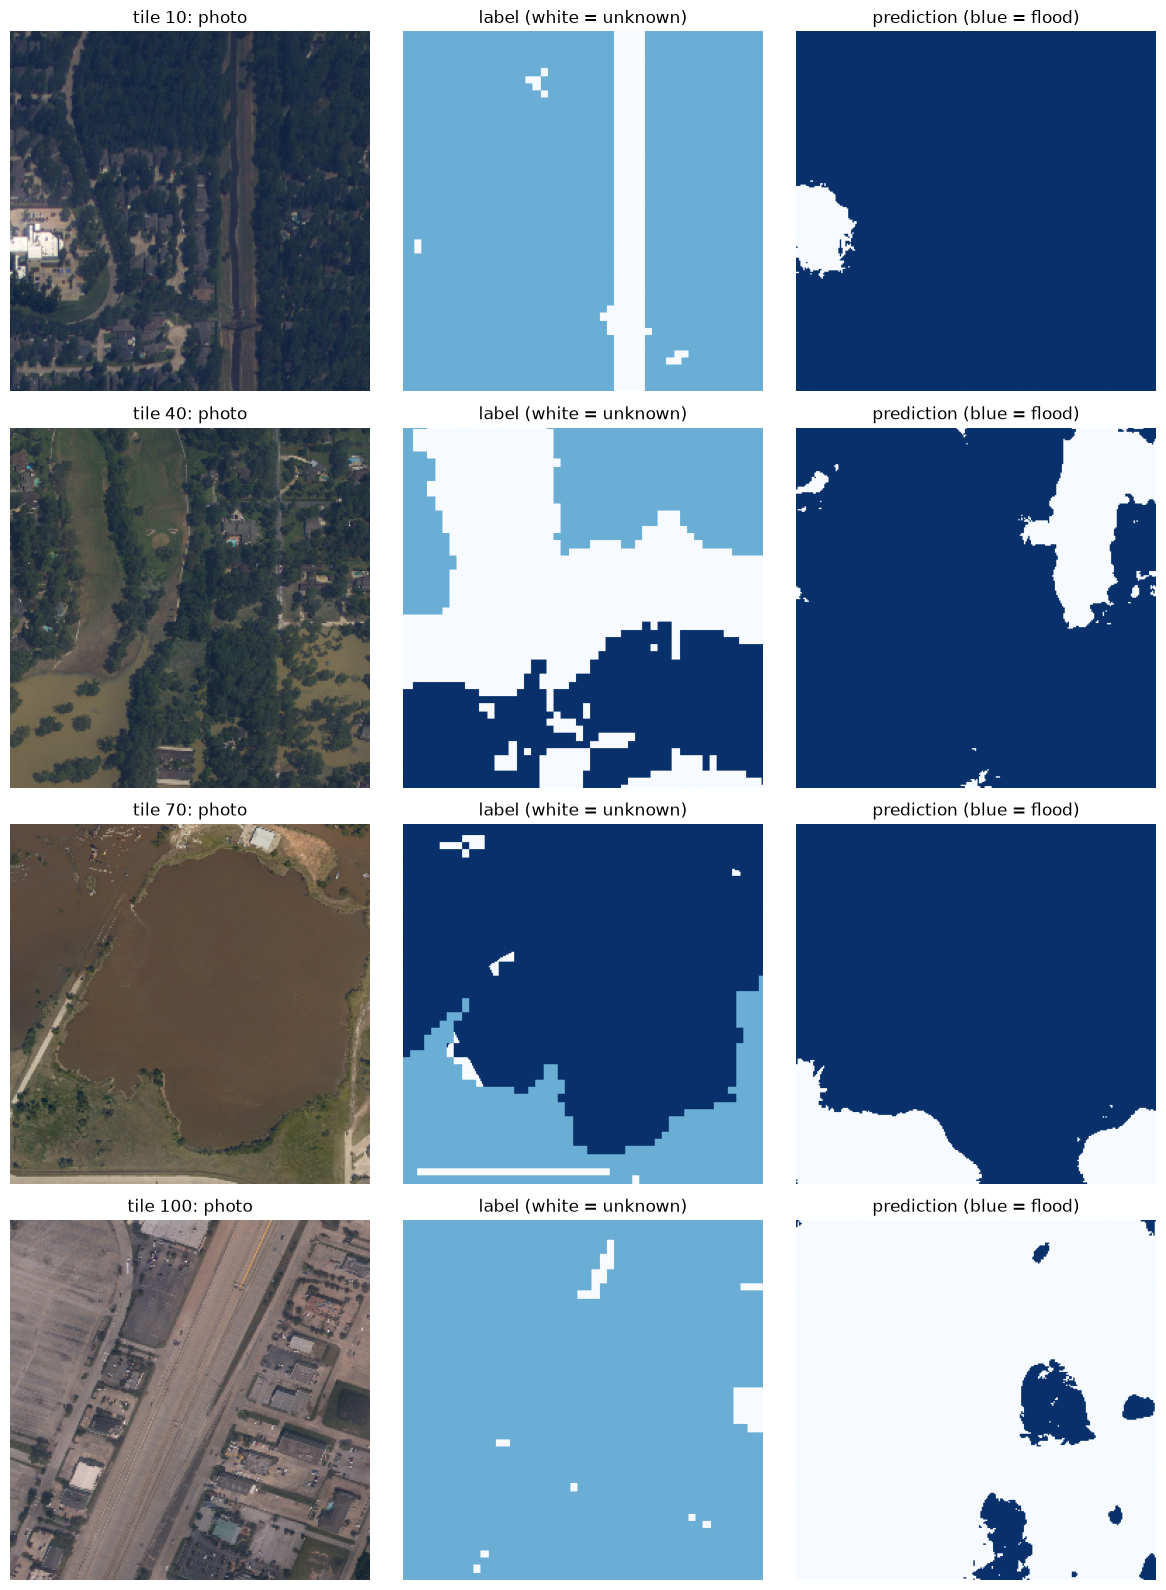

In [18]:
import matplotlib.pyplot as plt

tiles = [10, 40, 70, 100]   # 4 tiles from image 12 to look at

fig, axes = plt.subplots(len(tiles), 3, figsize=(12, 4 * len(tiles)))
for row, t in enumerate(tiles):
    axes[row, 0].imshow(X_val_rgb[t])                          # the photo
    axes[row, 1].imshow(y_val[t], cmap="Blues", vmin=-1, vmax=1)  # answer
    axes[row, 2].imshow(pred_flood[t], cmap="Blues")           # model's guess
    axes[row, 0].set_title(f"tile {t}: photo")
    axes[row, 1].set_title("label (white = unknown)")
    axes[row, 2].set_title("prediction (blue = flood)")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

Tile 10 (dense trees, all dry): the model calls almost all of it flood. Only the white building on the left is dry. 
Tile 40 (trees + brown floodwater): it finds the brown water at the bottom, but it also colors the trees and grass at the top as flood, which the label says are dry.
Tile 70 (big brown pond): did good. The pond is flood, the grass at the bottom is dry, and the edge is close to the actaul.
Tile 100 (city, roads, parking lots): pretty good. Almost all dry, with a few wrong blobs, that are darker buildings

In [19]:
CUTOFF = 0.5   


model.load_weights("../outputs/unet_phase1.weights.h5")

#predict on test
test_probs = model.predict(X_test_in, batch_size=8)[..., 0]


test_pred_flood = test_probs > CUTOFF
test_pred_dry = ~test_pred_flood


test_known = y_test != -1
test_true_flood = y_test == 1
test_true_dry = y_test == 0

test_iou_flood = np.sum(test_pred_flood & test_true_flood & test_known) / np.sum((test_pred_flood | test_true_flood) & test_known)
test_iou_dry = np.sum(test_pred_dry & test_true_dry & test_known) / np.sum((test_pred_dry | test_true_dry) & test_known)

print(f"TEST (cutoff {CUTOFF})")
print(f"flood IoU: {test_iou_flood:.3f}")
print(f"dry IoU:   {test_iou_dry:.3f}")
print(f"model says flood: {test_pred_flood[test_known].mean():.1%}   label says flood: {test_true_flood[test_known].mean():.1%}")

36/36 ━━━━━━━━━━━━━━━━━━━━ 14s 300ms/step
TEST (cutoff 0.5)
flood IoU: 0.753
dry IoU:   0.403
model says flood: 74.3%   label says flood: 76.0%


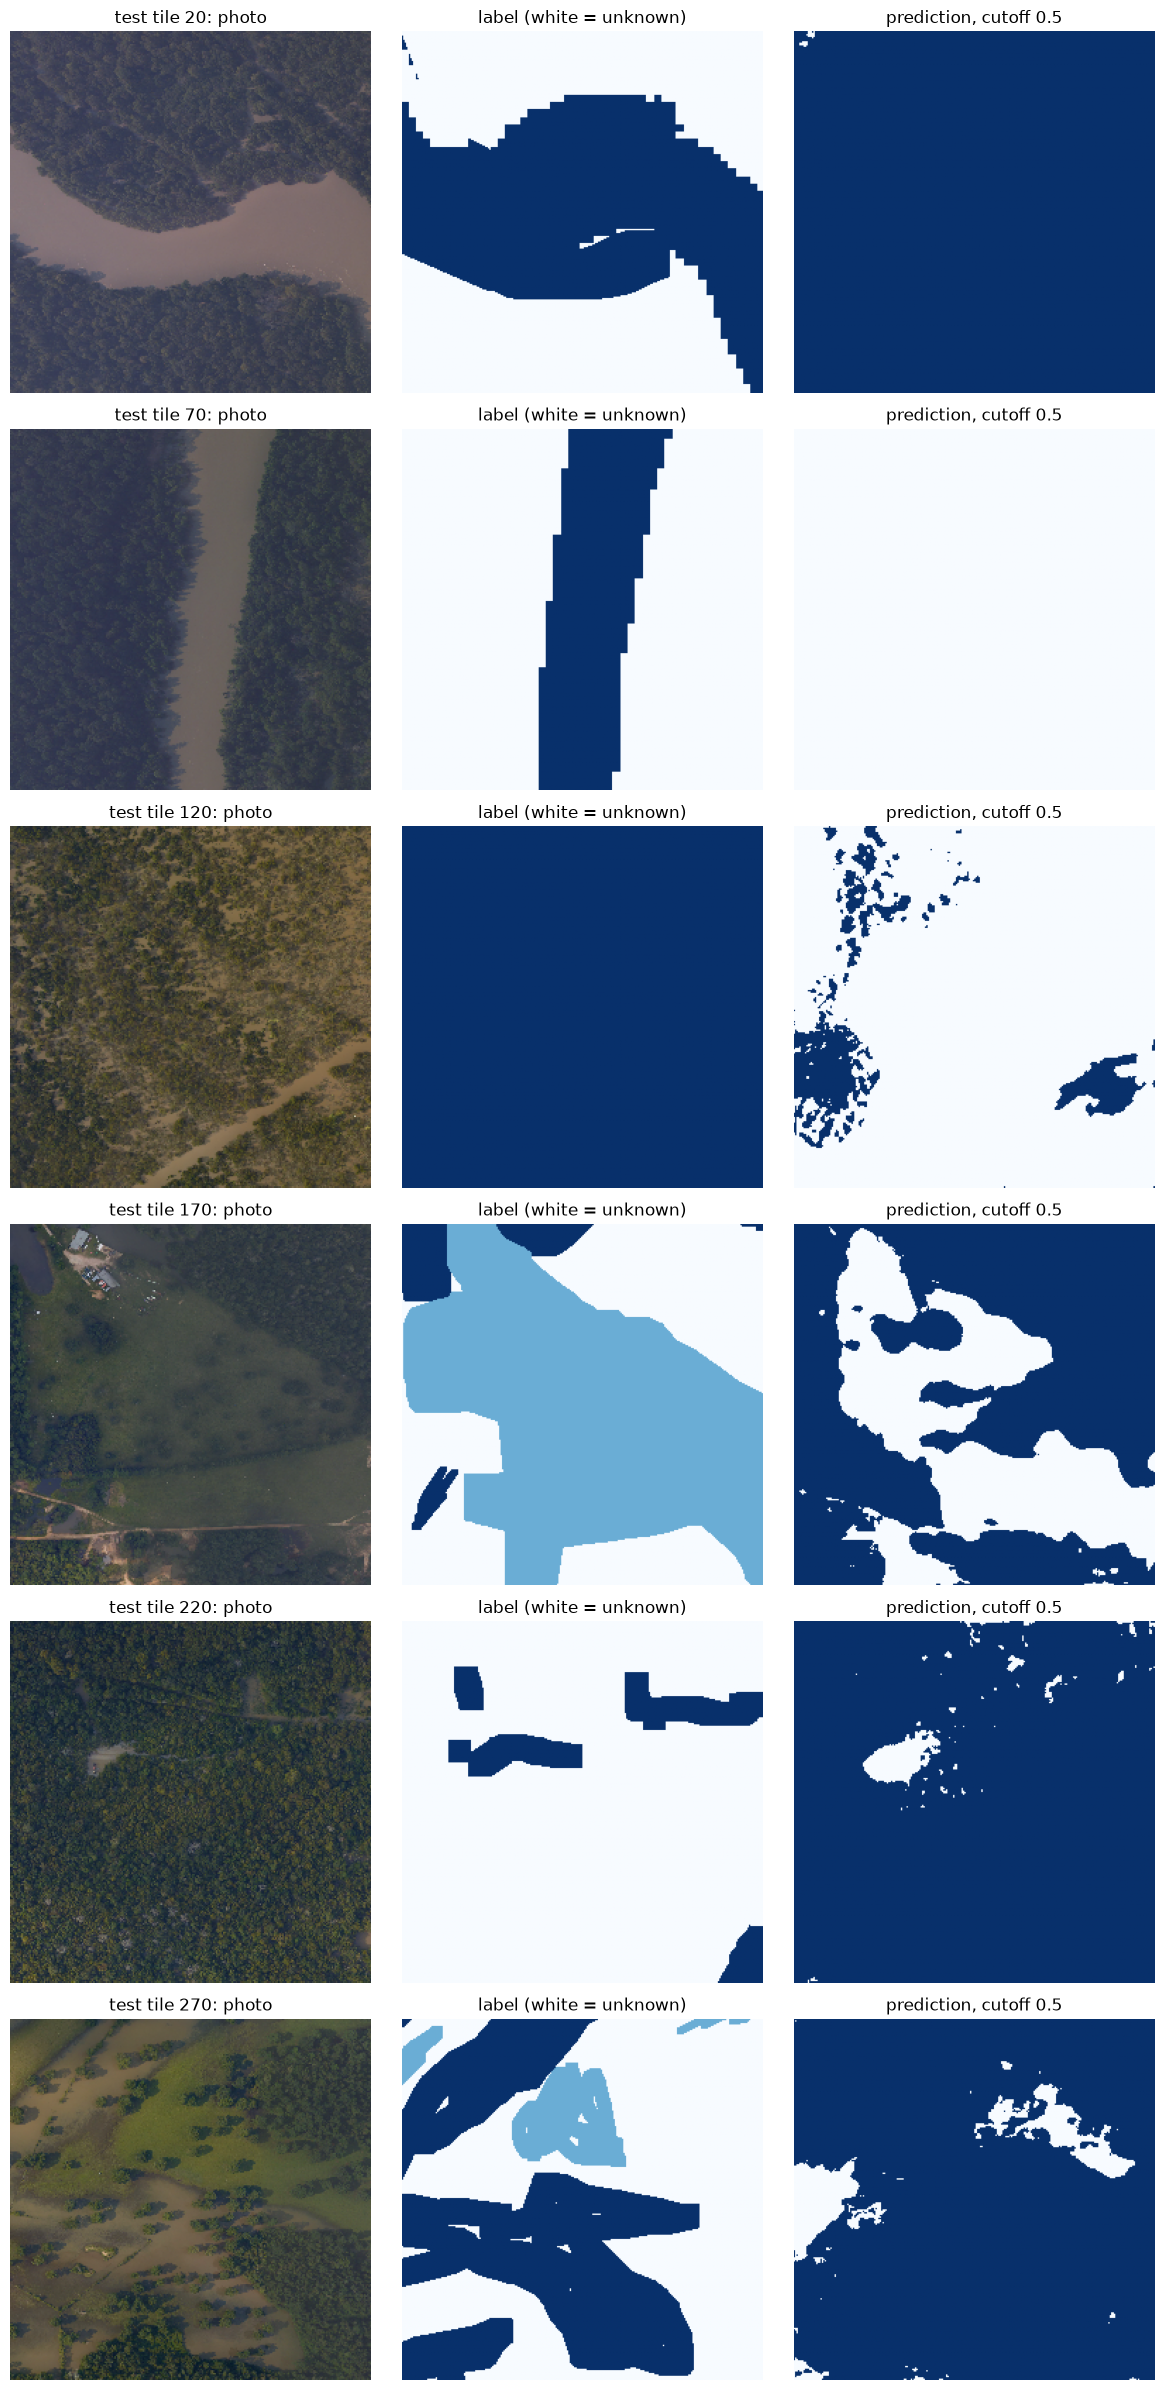

In [20]:
tiles = [20, 70, 120, 170, 220, 270]   
fig, axes = plt.subplots(len(tiles), 3, figsize=(12, 4 * len(tiles)))
for row, t in enumerate(tiles):
    axes[row, 0].imshow(X_test_rgb[t])                             
    axes[row, 1].imshow(y_test[t], cmap="Blues", vmin=-1, vmax=1)  
    axes[row, 2].imshow(test_pred_flood[t], cmap="Blues")          
    axes[row, 0].set_title(f"test tile {t}: photo")
    axes[row, 1].set_title("label (white = unknown)")
    axes[row, 2].set_title(f"prediction, cutoff {CUTOFF}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()